# Predicting Airline Satisfaction

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from mypkg import utils as u

print("Libraries imported successfully...Bliss")

Libraries imported successfully...Bliss


In [2]:
df_sample, df_test, df_train = u.load_data()

Dataset loaded successfully


In [3]:
display(df_sample.head())
display(df_test.head())
display(df_train.head())

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [4]:
u.print_shapes(sample_submission=df_sample, Test=df_test, Train=df_train)

sample_submission Data Shape:
Rows: 299844 | Columns: 2

Test Data Shape:
Rows: 299844 | Columns: 22

Train Data Shape:
Rows: 699635 | Columns: 23



In [5]:
u.print_column_lists(df_sample_list=df_sample, df_train_list=df_train, df_test_list=df_test)

df_sample_list
 ['id', 'satisfaction'] 

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 

df_test_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class'] 



In [6]:
u.print_target_distribution(df_train)

satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


## Missing values

In [7]:
u.print_missing_values(Train=df_train, Test=df_test)

Missing values in Train Data
Arrival Delay in Minutes    292
dtype: int64
--------------------------------------------------
Missing values in Test Data
Arrival Delay in Minutes    130
dtype: int64
--------------------------------------------------


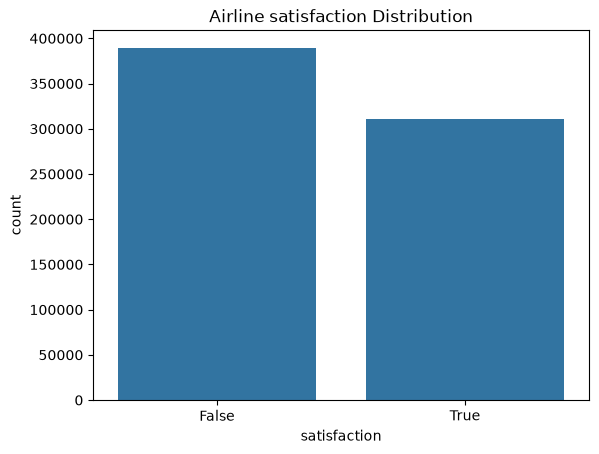

In [8]:
u.plot_target_distribution(df_train)
plt.show()

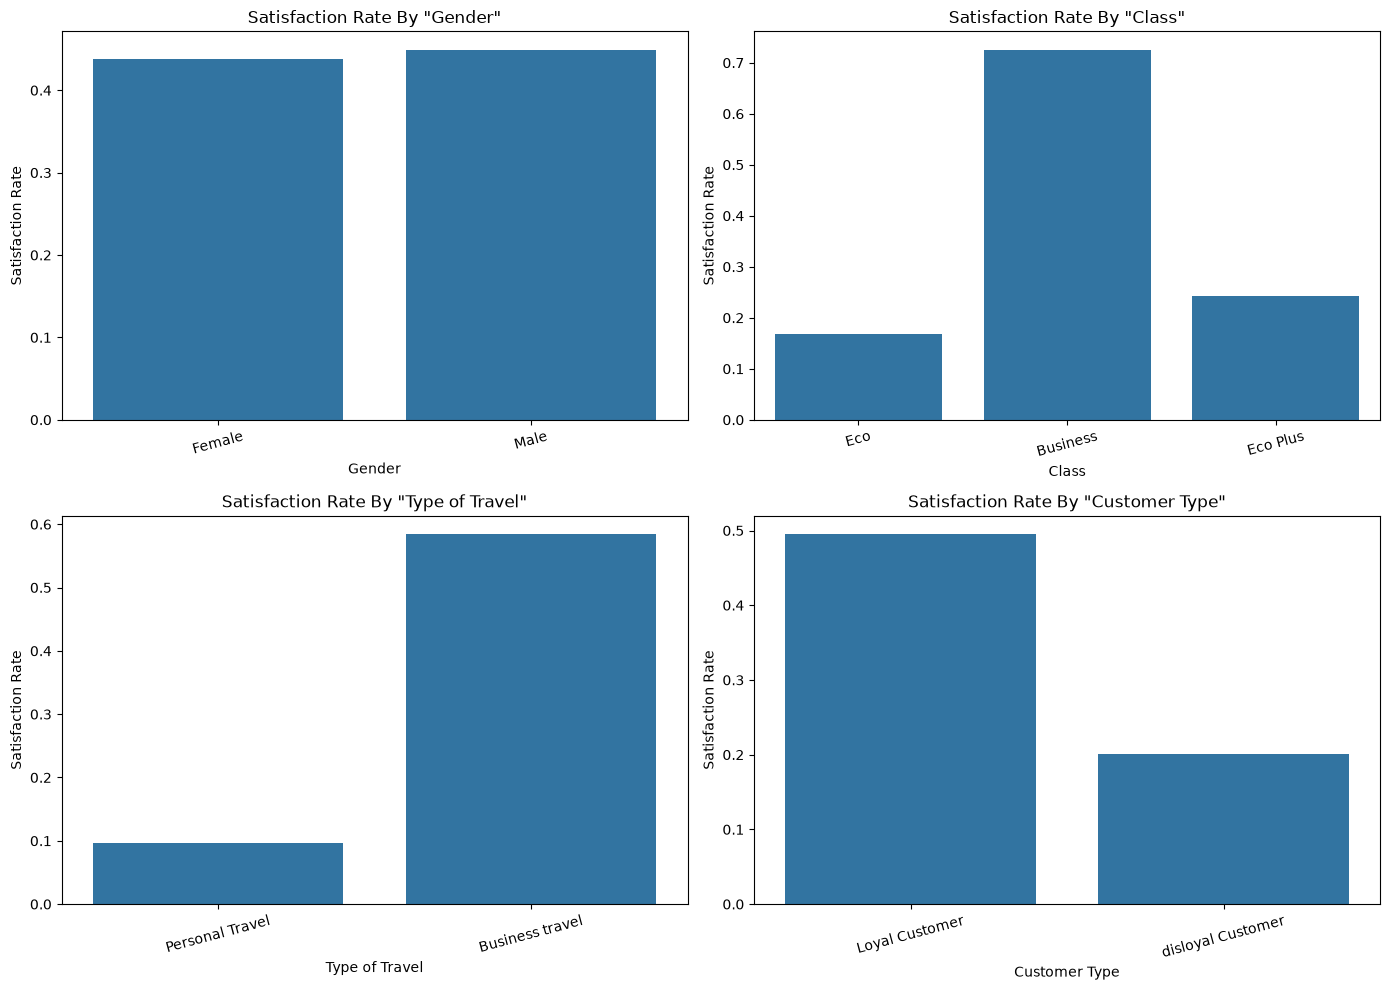

In [9]:
u.plot_categorical_satisfaction(df_train)
plt.show()

## Analyze airline service rating

In [10]:
ser_fest = u.find_matching_columns(df_train, u.SERVICE_KEYWORDS)
print("Service-related columns:")
print(ser_fest)

Service-related columns:
['Inflight wifi service', 'Ease of Online booking', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Checkin service', 'Cleanliness']


In [11]:
comparison = u.compare_service_ratings(df_train, ser_fest)
print(comparison.round(2))

satisfaction            False  True 
Inflight wifi service    2.45   3.20
Ease of Online booking   2.59   3.10
Food and drink           3.01   3.58
Online boarding          2.72   4.17
Seat comfort             3.11   4.14
Inflight entertainment   2.95   4.09
On-board service         3.13   4.00
Leg room service         3.10   3.94
Checkin service          3.15   3.76
Cleanliness              2.99   3.87


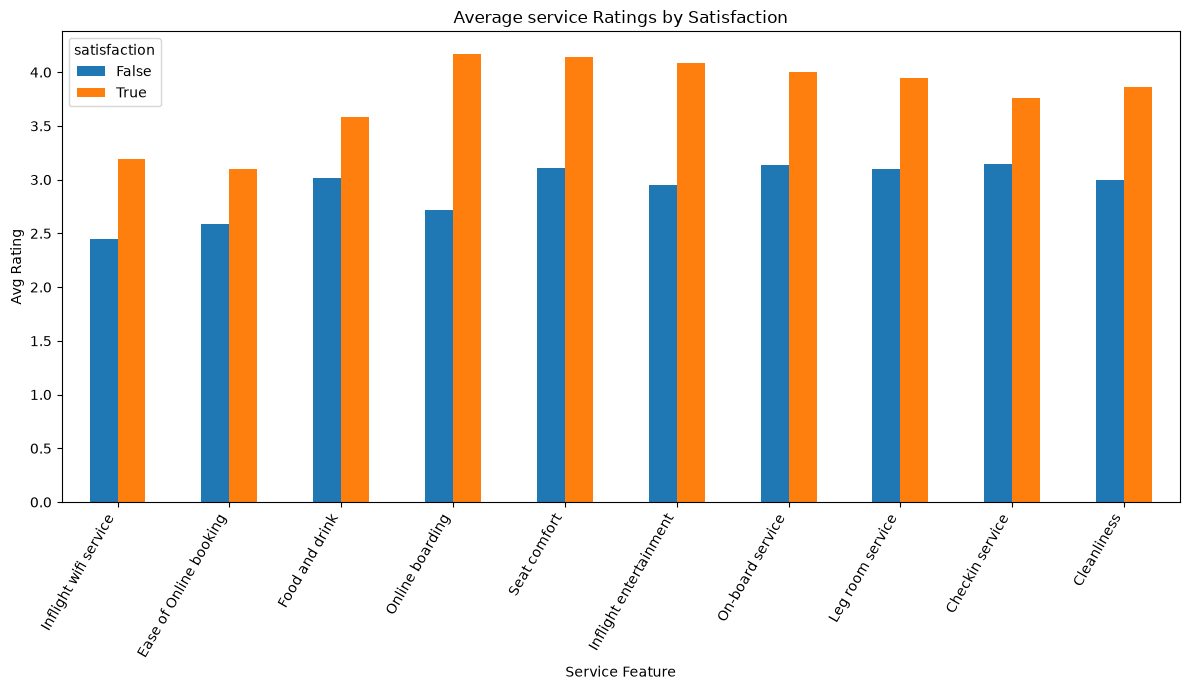

In [12]:
# Visualize the difference
u.plot_service_ratings(comparison)
plt.show()

## Analyze flight delays

In [13]:
delay_fest = u.find_matching_columns(df_train, u.DELAY_KEYWORDS)
print("Delay-related columns:")
print(delay_fest)

Delay-related columns:
['Departure Delay in Minutes', 'Arrival Delay in Minutes']


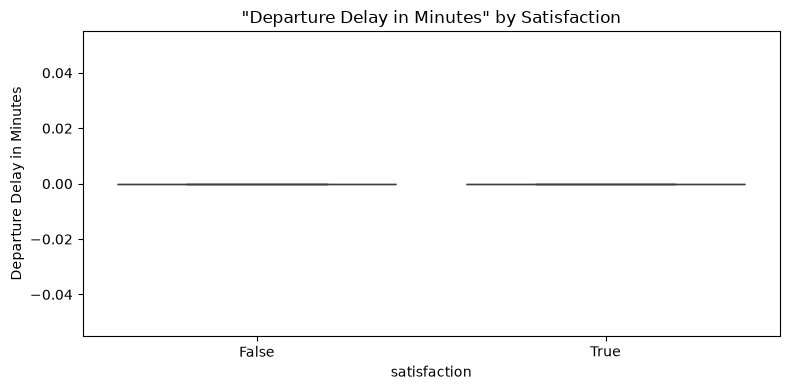

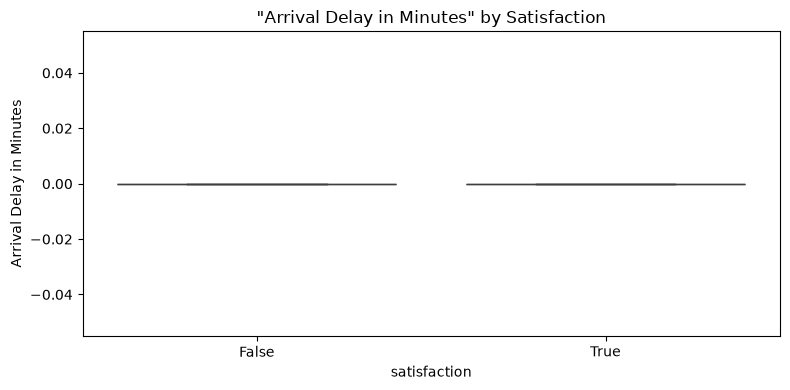

In [14]:
# Visualize the distribution
u.plot_delay_boxplots(df_train, delay_fest)
plt.show()

## Analyze numerical feature

In [15]:
num_cols = u.get_numeric_columns(df_train)
print(num_cols)

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [16]:
# summary statistics
display(u.summarise_numeric(df_train, num_cols))

,mean,std,min,25%,50%,75%,max
Age,39.00,13.80,7.0,27.0,40.0,50.0,85.0
Flight Distance,1353.78,954.42,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,2.78,1.28,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,3.16,1.48,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,2.81,1.33,0.0,2.0,3.0,4.0,5.0
Gate location,3.01,1.25,0.0,2.0,3.0,4.0,5.0
Food and drink,3.27,1.30,0.0,2.0,3.0,4.0,5.0
Online boarding,3.36,1.29,0.0,2.0,4.0,4.0,5.0
Seat comfort,3.57,1.28,0.0,3.0,4.0,5.0,5.0
Inflight entertainment,3.45,1.31,0.0,2.0,4.0,5.0,5.0


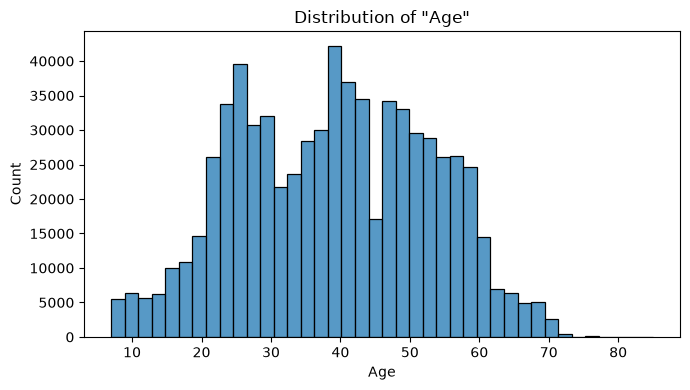

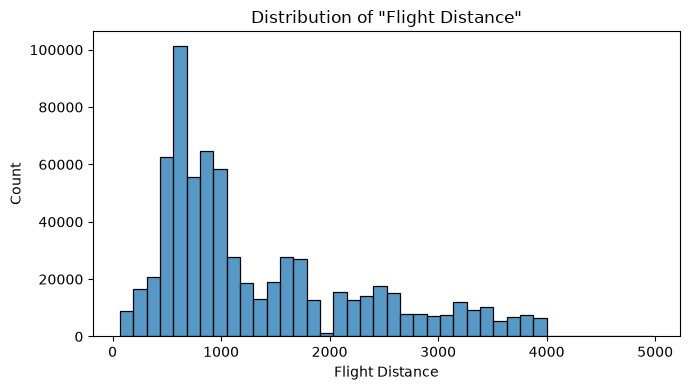

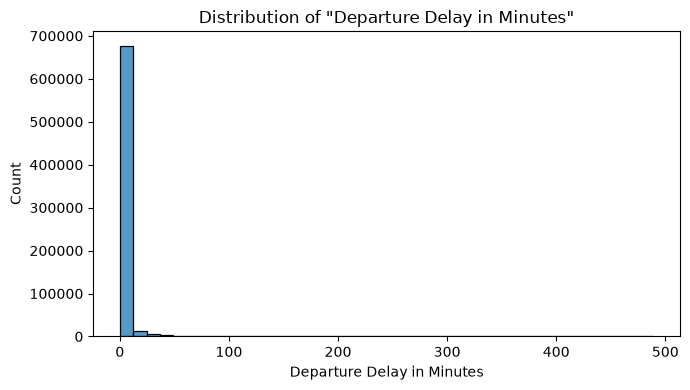

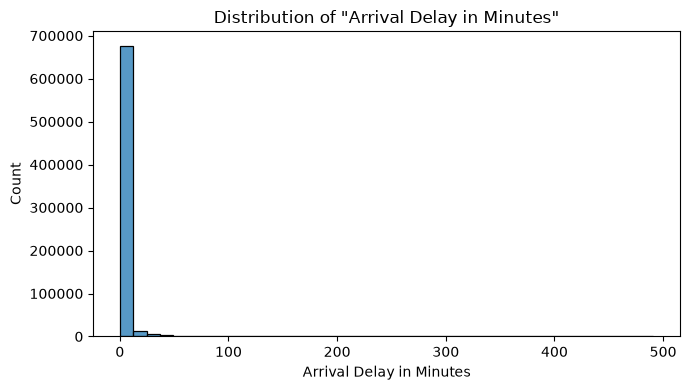

In [17]:
# plot numerical distributions
u.plot_numeric_distributions(df_train)
plt.show()

## Correlation analysis

In [18]:
corr_data, target_corr = u.target_correlations(df_train, num_cols)
display(target_corr.to_frame("Correlation with satisfaction").round(3))

,Correlation with satisfaction
Online boarding,0.560
Inflight entertainment,0.431
Seat comfort,0.401
Flight Distance,0.370
On-board service,0.347
Cleanliness,0.339
Leg room service,0.330
Inflight wifi service,0.291
Baggage handling,0.258
Checkin service,0.250


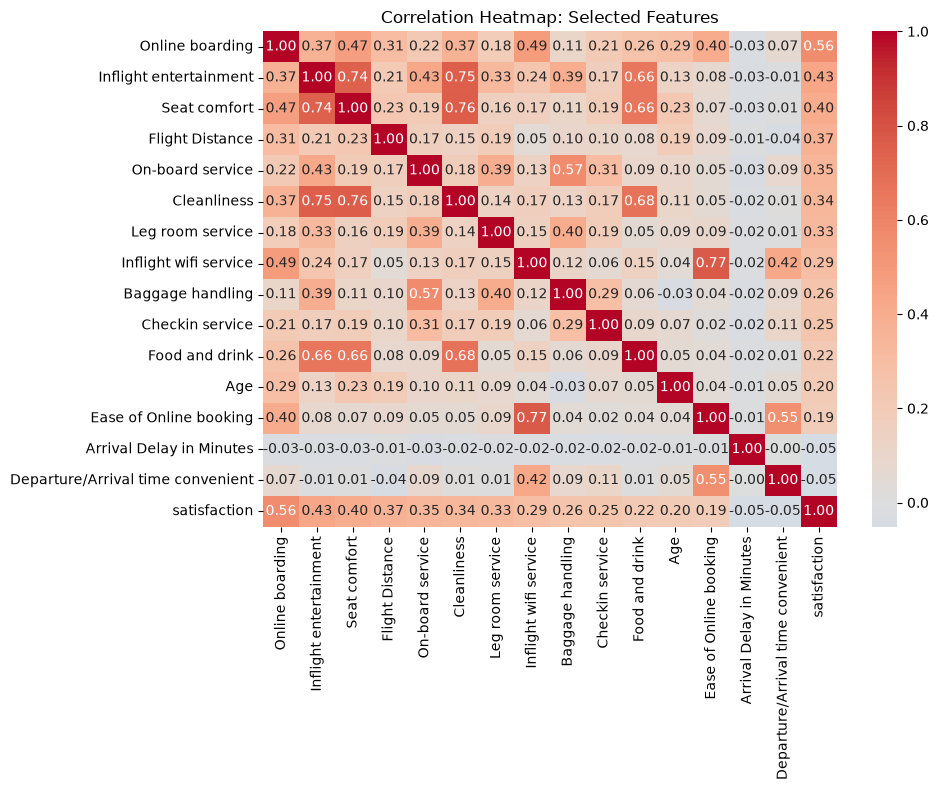

In [19]:
u.plot_correlation_heatmap(corr_data, target_corr)
plt.show()

## EDA Conclusion

In [20]:
for key, value in u.eda_summary(df_train, df_test).items():
    print(f"{key}: {value}")

training_rows: 699635
training_columns: 23
test_rows: 299844
missing_train_values: 292
duplicated_train_rows: 0
satisfied_percentage: 44.36
not_satisfied_percentage: 55.64


## Data Preprocessing

### Separate features and target

In [21]:
X, y, X_df_test, test_ids, cat_features, num_features = u.prepare_features(df_train, df_test)

X shape: (699635, 21)
y shape: (699635,)
No. of categorical columns: 4
No. of numerical columns: 17
----------------------------------------------------------------------
categorical columns:
['Gender', 'Customer Type', 'Type of Travel', 'Class']
----------------------------------------------------------------------
numerical columns:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


## Splitting data and building pipeline
*We train and test different types of ML models for better predictions*

### Logistic Regression

In [22]:
X_train, X_test, y_train, y_test = u.split_data(X, y)

preprocessor = u.build_preprocessor(num_features, cat_features)
model = u.build_logistic_model(preprocessor)

print("Preprocessing and model pipeline ready!")

Preprocessing and model pipeline ready!


In [23]:
y_pred = u.evaluate_logistic(model, X_train, y_train, X_test, y_test)

Accuracy: 0.8780864307817647
F1 binary: 0.8602923713197658
F1 macro: 0.8760761123155194
F1 weighted: 0.8778573343388884
--------------------------------------------------------------------------------

Confusion matrix:
[[70345  7514]
 [ 9545 52523]]
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.88      0.90      0.89     77859
           1       0.87      0.85      0.86     62068

    accuracy                           0.88    139927
   macro avg       0.88      0.87      0.88    139927
weighted avg       0.88      0.88      0.88    139927



### Random Forest Classifier

In [24]:
rf_model = u.build_random_forest(preprocessor)
rf_results = u.fit_and_evaluate(rf_model, "Random Forest", X_train, y_train, X_test, y_test)

Random Forest training started...
Training completed

======= Random Forest Result ============
Accuracy:  0.92153
F1 Score:  0.91073
ROC-AUC:  0.95541
Training Time:  18.8 seconds


## Gradient Boosting Classifier

In [25]:
gcb_model = u.build_gradient_boosting(preprocessor)
gcb_results = u.fit_and_evaluate(gcb_model, "Gradient Boosting", X_train, y_train, X_test, y_test)

Gradient Boosting training started...
Training completed

======= Gradient Boosting Result ============
Accuracy:  0.911
F1 Score:  0.89837
ROC-AUC:  0.95116
Training Time:  205.4 seconds


In [26]:
print(f"Till now {u.pick_best_model(rf_results, gcb_results)} successful")

Till now Random Forest successful
